# Step 3: Baseline LightGBM Fraud Model

**Project:** Chargeback Reduction for NovaCart ([business brief](../docs/business_brief.md))

Step 2 showed NovaCart loses about **$619k a month** to fraud (3.5% of transactions). This step builds the
**risk-scoring engine**: a model that gives every transaction a score between 0 and 1.

**Design decisions (and why):**

| Decision | Why |
|---|---|
| **LightGBM** | Fast, strong on tabular data, handles missing values and categories natively |
| **Split by time, not at random** | Fraud patterns drift. A random split leaks "future" behaviour into training and flatters the model |
| **Train → validation → 30-day gap → test** | Validation is used for early stopping now and for choosing thresholds in Step 4. The gap mimics production, where the latest chargebacks haven't arrived yet. Test is the untouched "final exam" |
| **No oversampling / SMOTE, no class weights** | Keeps scores close to real probabilities, which the cost model in Step 4 needs |
| **PR-AUC, not accuracy** | 96.5% of orders are genuine, so "approve everything" is 96.5% accurate and useless |
| **Business metrics** | What share of fraud *dollars* we catch when we flag the riskiest X% of orders, and how precise a 100-a-day review queue would be |

In [13]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
SEED = 42

GENUINE, FRAUD, MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "lines.linewidth": 2,
})

# Locally (run from notebooks/) outputs go into the repo; on Kaggle into /kaggle/working.
IN_REPO  = Path("../reports").exists()
OUT_DIR  = Path("../reports") if IN_REPO else Path(".")
ART_DIR  = Path("../artifacts") if IN_REPO else Path("artifacts")   # predictions + model (not committed to git)
FIG_DIR  = OUT_DIR / "figures"
for d in (FIG_DIR, ART_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the data
Same loader and curated columns as Step 2.

In [14]:
def find_file(name):
    roots = [os.environ.get("FRAUD_DATA_DIR"), "/kaggle/input", "../data", "data"]
    for root in filter(None, roots):
        root = Path(root)
        if root.exists():
            hits = sorted(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. On Kaggle: Add Input -> Competitions -> IEEE-CIS Fraud Detection.")

ORDER      = ["TransactionAmt", "ProductCD"]
CARD       = ["card1", "card2", "card3", "card4", "card5", "card6"]
LOCATION   = ["addr1", "addr2", "dist1"]
EMAIL      = ["P_emaildomain", "R_emaildomain"]
COUNTS     = [f"C{i}" for i in range(1, 15)]
TIMEDELTAS = ["D1", "D4", "D10", "D15"]
MATCHES    = [f"M{i}" for i in range(1, 10)]
CATEGORICAL = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain"] + MATCHES
USE_COLS = ["TransactionID", "isFraud", "TransactionDT"] + ORDER + CARD + LOCATION + EMAIL + COUNTS + TIMEDELTAS + MATCHES

df = pd.read_csv(find_file("train_transaction.csv"), usecols=USE_COLS, dtype={c: "category" for c in CATEGORICAL})
for c in df.columns:
    if c in CATEGORICAL or c == "TransactionAmt":
        continue
    if pd.api.types.is_float_dtype(df[c]):
        df[c] = df[c].astype("float32")

df["day"] = (df["TransactionDT"] // 86_400).astype("int32")
df["day"] -= df["day"].min()
print(f"{len(df):,} transactions over {df['day'].max() + 1} days")

590,540 transactions over 182 days


## 2. Two simple, explainable features
We deliberately keep feature engineering minimal. Two additions that a fraud analyst would recognise:

- **`hour`**: hour of day (relative to the dataset's hidden clock). Fraud often clusters at unusual hours.
- **`amt_cents`**: the cents part of the amount. Genuine prices tend to end in .99 or .00; odd amounts can indicate currency conversion, which is common in cross-border fraud.

In [15]:
df["hour"] = ((df["TransactionDT"] % 86_400) // 3_600).astype("int8")
df["amt_cents"] = ((df["TransactionAmt"] * 100).round() % 100).astype("int16")

FEATURES = ORDER + CARD + LOCATION + EMAIL + COUNTS + TIMEDELTAS + MATCHES + ["hour", "amt_cents"]
TARGET = "isFraud"
print(f"{len(FEATURES)} features ({sum(df[f].dtype == 'category' for f in FEATURES)} categorical)")

42 features (14 categorical)


## 3. Time-based split

```
day 0 ─────────── train ──────────── 101 │ 102 ── validation ── 121 │ 122 ── gap ── 151 │ 152 ── test ── 181
```

- **Train** (~102 days): the model learns patterns.
- **Validation** (20 days): early stopping now; calibration and threshold choice in Step 4.
- **Gap** (30 days, unused): chargebacks take weeks to arrive, so in production the latest month has no labels yet.
- **Test** (30 days): touched once, to report final results.

In [16]:
VAL_DAYS, GAP_DAYS, TEST_DAYS = 20, 30, 30
n_days     = df["day"].max() + 1
test_start = n_days - TEST_DAYS
gap_start  = test_start - GAP_DAYS
val_start  = gap_start - VAL_DAYS

df["split"] = np.select(
    [df["day"] < val_start, df["day"] < gap_start, df["day"] < test_start],
    ["train", "validation", "gap"], "test")

train, val, test = (df[df["split"] == s] for s in ["train", "validation", "test"])

split_table = df.groupby("split").agg(first_day=("day", "min"), last_day=("day", "max"),
                                      transactions=(TARGET, "size"), fraud_rate=(TARGET, "mean"))
split_table.loc[["train", "validation", "gap", "test"]]

,first_day,last_day,transactions,fraud_rate
split,,,,
train,0,101,359382,0.0338
validation,102,121,60684,0.0435
gap,122,151,85044,0.0339
test,152,181,85430,0.0350


## 4. Train the model
Moderate, commonly used settings. Early stopping on validation **PR-AUC** picks the number of trees,
so we don't need to guess it (and we never look at the test set while tuning).

In [17]:
model = lgb.LGBMClassifier(
    n_estimators=3_000,
    learning_rate=0.03,
    num_leaves=64,
    min_child_samples=100,     # each leaf needs 100+ orders: avoids memorising rare cases
    subsample=0.8, subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
)

model.fit(
    train[FEATURES], train[TARGET],
    eval_set=[(val[FEATURES], val[TARGET])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(150, verbose=False), lgb.log_evaluation(250)],
)
print(f"Best number of trees: {model.best_iteration_}")

[250]	valid_0's average_precision: 0.59907	valid_0's binary_logloss: 0.102469
[500]	valid_0's average_precision: 0.612097	valid_0's binary_logloss: 0.0999939
[750]	valid_0's average_precision: 0.621093	valid_0's binary_logloss: 0.0989724
[1000]	valid_0's average_precision: 0.626162	valid_0's binary_logloss: 0.0987461
Best number of trees: 1072


## 5. Model quality: PR-AUC

In [18]:
val_score  = model.predict_proba(val[FEATURES])[:, 1]
test_score = model.predict_proba(test[FEATURES])[:, 1]

metrics = pd.DataFrame({
    "fraud rate (= PR-AUC of random guessing)": [val[TARGET].mean(), test[TARGET].mean()],
    "PR-AUC":  [average_precision_score(val[TARGET], val_score), average_precision_score(test[TARGET], test_score)],
    "ROC-AUC": [roc_auc_score(val[TARGET], val_score), roc_auc_score(test[TARGET], test_score)],
}, index=["validation", "test"])
metrics["PR-AUC lift vs random"] = metrics["PR-AUC"] / metrics["fraud rate (= PR-AUC of random guessing)"]
metrics

,fraud rate (= PR-AUC of random guessing),PR-AUC,ROC-AUC,PR-AUC lift vs random
validation,0.0435,0.6273,0.9280,14.4143
test,0.0350,0.4985,0.8923,14.2231


**How to read this:** PR-AUC summarises precision vs recall across all thresholds. A random model scores
the fraud rate (about 0.035); the lift column shows how many times better the model is.
ROC-AUC is reported because it's familiar, but it looks flattering on imbalanced data, so PR-AUC is the headline.

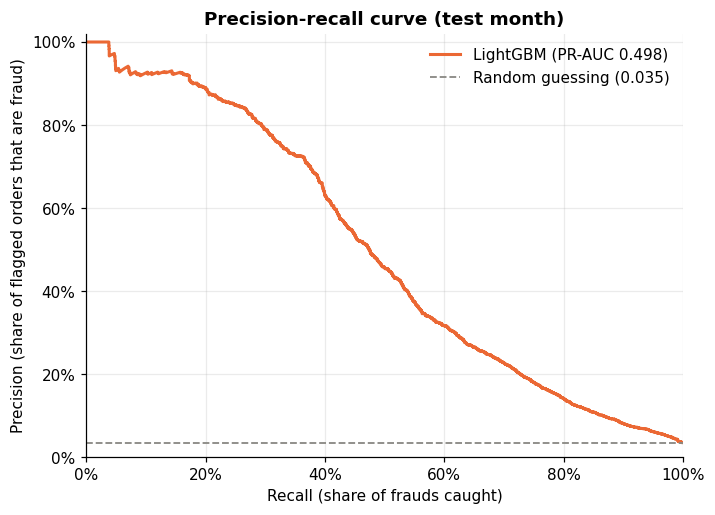

In [19]:
prec, rec, _ = precision_recall_curve(test[TARGET], test_score)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(rec, prec, color=FRAUD, label=f"LightGBM (PR-AUC {metrics.loc['test', 'PR-AUC']:.3f})")
ax.axhline(test[TARGET].mean(), color=MUTED, ls="--", lw=1.2, label=f"Random guessing ({test[TARGET].mean():.3f})")
ax.set_xlabel("Recall (share of frauds caught)")
ax.set_ylabel("Precision (share of flagged orders that are fraud)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curve (test month)")
ax.legend(frameon=False)
save(fig, "10_pr_curve_test"); plt.show()

## 6. Business view: what does flagging the riskiest orders catch?
If NovaCart acted on the riskiest **X%** of orders (decline or step-up), how much fraud, and how many fraud **dollars**, would it stop,
and how many genuine customers would be affected? This is the bridge to Step 4's cost optimisation.

In [20]:
def capture_table(frame, score, rates=(0.005, 0.01, 0.02, 0.03, 0.05, 0.10)):
    y, amt = frame[TARGET].to_numpy(), frame["TransactionAmt"].to_numpy()
    rows = []
    for r in rates:
        cut = np.quantile(score, 1 - r)
        flag = score >= cut
        rows.append({
            "flag riskiest": f"{r:.1%}",
            "orders flagged": int(flag.sum()),
            "precision": y[flag].mean(),
            "frauds caught (recall)": y[flag].sum() / y.sum(),
            "fraud $ caught": amt[flag & (y == 1)].sum() / amt[y == 1].sum(),
            "genuine customers flagged": (flag & (y == 0)).sum() / (y == 0).sum(),
        })
    return pd.DataFrame(rows).set_index("flag riskiest")

capture = capture_table(test, test_score)
capture.style.format({"orders flagged": "{:,}", "precision": "{:.1%}", "frauds caught (recall)": "{:.1%}",
                      "fraud $ caught": "{:.1%}", "genuine customers flagged": "{:.2%}"})

,orders flagged,precision,frauds caught (recall),fraud $ caught,genuine customers flagged
flag riskiest,,,,,
0.5%,428,92.8%,13.3%,6.8%,0.04%
1.0%,855,85.3%,24.3%,12.7%,0.15%
2.0%,"1,709",67.8%,38.7%,24.9%,0.67%
3.0%,"2,563",52.9%,45.3%,31.7%,1.47%
5.0%,"4,272",38.3%,54.6%,45.8%,3.20%
10.0%,"8,543",24.0%,68.4%,65.8%,7.88%


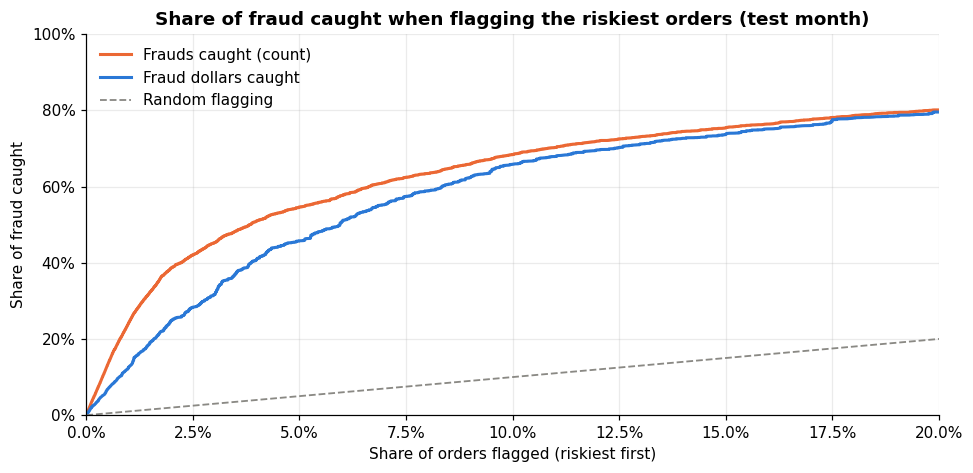

In [21]:
order = np.argsort(-test_score)
y_sorted = test[TARGET].to_numpy()[order]
amt_sorted = test["TransactionAmt"].to_numpy()[order]
share_flagged = np.arange(1, len(order) + 1) / len(order)
fraud_count_caught = np.cumsum(y_sorted) / y_sorted.sum()
fraud_dollars_caught = np.cumsum(amt_sorted * y_sorted) / (amt_sorted * y_sorted).sum()

fig, ax = plt.subplots()
ax.plot(share_flagged, fraud_count_caught, color=FRAUD, label="Frauds caught (count)")
ax.plot(share_flagged, fraud_dollars_caught, color=GENUINE, label="Fraud dollars caught")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1.2, label="Random flagging")
ax.set_xlim(0, 0.2); ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of orders flagged (riskiest first)")
ax.set_ylabel("Share of fraud caught")
ax.set_title("Share of fraud caught when flagging the riskiest orders (test month)")
ax.legend(frameon=False, loc="upper left")
save(fig, "11_fraud_capture_curve"); plt.show()

### The 100-a-day review queue
Step 2 showed only 100 orders a day can be reviewed. If each day analysts took the **100 highest-scoring orders**,
how many would actually be fraud?

In [22]:
t = test.assign(score=test_score)
top100 = t.sort_values("score", ascending=False).groupby("day").head(100)
per_day = top100.groupby("day")[TARGET].agg(frauds_in_queue="sum", queue_size="size")
per_day["frauds_that_day"] = t.groupby("day")[TARGET].sum()

queue = {
    "precision_of_top100_per_day": float(per_day["frauds_in_queue"].sum() / per_day["queue_size"].sum()),
    "avg_frauds_in_queue_per_day": float(per_day["frauds_in_queue"].mean()),
    "avg_frauds_per_day": float(per_day["frauds_that_day"].mean()),
}
queue["share_of_daily_fraud_in_queue"] = queue["avg_frauds_in_queue_per_day"] / queue["avg_frauds_per_day"]
pd.Series(queue).to_frame("value")

,value
precision_of_top100_per_day,0.4813
avg_frauds_in_queue_per_day,48.1333
avg_frauds_per_day,99.8000
share_of_daily_fraud_in_queue,0.4823


## 7. What drives the score?
**Gain importance**: how much each feature improved the model's splits overall. This is a first look;
Step 5 uses SHAP to explain *individual* decisions ("why was this order flagged?").

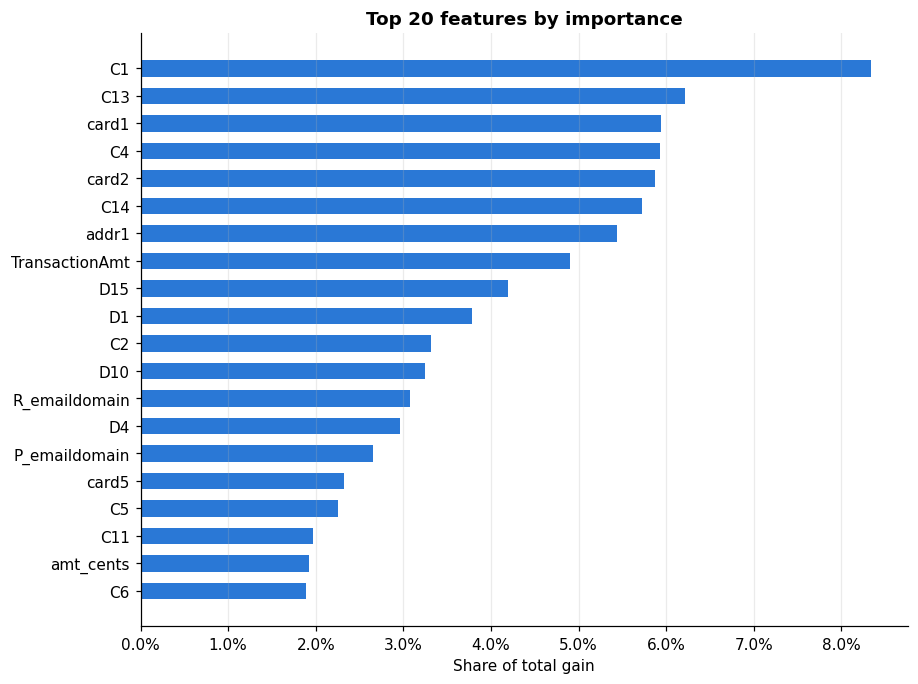

,share_of_gain
C1,0.0834
C13,0.0622
card1,0.0595
C4,0.0593
card2,0.0587
C14,0.0572
addr1,0.0544
TransactionAmt,0.0490
D15,0.0419
D1,0.0378


In [23]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES).sort_values(ascending=False)
imp_share = imp / imp.sum()
top = imp_share.head(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color=GENUINE, height=0.6)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of total gain")
ax.set_title("Top 20 features by importance")
ax.grid(axis="y", visible=False)
save(fig, "12_feature_importance"); plt.show()

imp_share.head(20).to_frame("share_of_gain")

## 8. Save outputs for Step 4
- **Predictions** for validation and test (TransactionID, day, amount, label, score). Step 4 calibrates scores and picks the
  three-tier thresholds on **validation**, then reports the final result on **test**.
- **The model** (LightGBM text format) and a **metrics summary**.

On Kaggle, use **Save Version** so Step 4 can add this notebook's output as an input.

In [24]:
keep = ["TransactionID", "day", "TransactionAmt", TARGET]
val.assign(score=val_score)[keep + ["score"]].to_parquet(ART_DIR / "predictions_val.parquet", index=False)
test.assign(score=test_score)[keep + ["score"]].to_parquet(ART_DIR / "predictions_test.parquet", index=False)
model.booster_.save_model(str(ART_DIR / "lgbm_step3.txt"))

summary = {
    "split_days": {"train": [0, int(val_start - 1)], "validation": [int(val_start), int(gap_start - 1)],
                   "gap": [int(gap_start), int(test_start - 1)], "test": [int(test_start), int(n_days - 1)]},
    "n_features": len(FEATURES),
    "best_iteration": int(model.best_iteration_),
    "metrics": {split: {k: float(v) for k, v in row.items()} for split, row in metrics.iterrows()},
    "capture_test": {k: {c: float(v) for c, v in row.items()} for k, row in capture.iterrows()},
    "review_queue_test": queue,
    "top10_features": imp_share.head(10).round(4).to_dict(),
}
(OUT_DIR / "step3_metrics.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "split_days": {
    "train": [
      0,
      101
    ],
    "validation": [
      102,
      121
    ],
    "gap": [
      122,
      151
    ],
    "test": [
      152,
      181
    ]
  },
  "n_features": 42,
  "best_iteration": 1072,
  "metrics": {
    "validation": {
      "fraud rate (= PR-AUC of random guessing)": 0.04352053259508273,
      "PR-AUC": 0.6273196420695448,
      "ROC-AUC": 0.9279764862205756,
      "PR-AUC lift vs random": 14.41433743254383
    },
    "test": {
      "fraud rate (= PR-AUC of random guessing)": 0.03504623668500527,
      "PR-AUC": 0.4984672221532695,
      "ROC-AUC": 0.8922901462264299,
      "PR-AUC lift vs random": 14.223131191901741
    }
  },
  "capture_test": {
    "0.5%": {
      "orders flagged": 428.0,
      "precision": 0.927570093457944,
      "frauds caught (recall)": 0.1325985303941216,
      "fraud $ caught": 0.06848884224081425,
      "genuine customers flagged": 0.000376049298850017
    },
    "1.0%": {
      "orders flagged": 855

## Findings

- **The model is 14× better than random on an unseen month.** Test PR-AUC is 0.50 (random = 0.035) and ROC-AUC is 0.89. The lift over random is almost identical on validation (14.4×) and test (14.2×), so performance held up across the 30-day gap.
- **The riskiest orders are very precise.** The top 0.5% of scores are 93% fraud. Flagging the riskiest 3% catches 45% of frauds while touching only 1.5% of genuine customers.
- **A 100-a-day review queue built from the top scores would be 48% fraud**, about 14× the base rate, catching roughly half of each day's frauds.
- **The model catches cheap fraud first.** At every cut-off it catches a smaller share of fraud *dollars* than fraud *count* (top 0.5%: 13% of frauds but only 7% of fraud dollars). High-value fraud looks more like normal behaviour, so Step 4 will rank orders by **expected dollar loss (probability × amount)**, not probability alone.
- **Strongest signals:** count features (C1, C13, C4, C14), card attributes (card1, card2), billing area (addr1), order amount, and account-age features (D15, D1).

**Next:** Step 4 turns scores into the three-tier policy (approve / step-up / decline + review) by minimising total dollar cost, within the 100-a-day review limit.